In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", None)

In [3]:
df = pd.read_csv("ai4i2020.csv")

In [4]:
df.head(10)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


In [5]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

(10000, 14)

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


## Data Dictionary
| Variable | Description | Role |
|---|---|---|
| `UDI` | Unique observation identifier | Identifier |
| `Product ID` | Product/machine identifier | Identifier |
| `Type` | Machine quality type: L, M, or H | Feature |
| `Air temperature [K]` | Ambient air temperature | Feature |
| `Process temperature [K]` | Machine process temperature | Feature |
| `Rotational speed [rpm]` | Rotational speed of the machine | Feature |
| `Torque [Nm]` | Applied torque | Feature |
| `Tool wear [min]` | Accumulated tool wear | Feature |
| `Machine failure` | Indicates whether a failure occurred | **Target** |
| `TWF` | Tool Wear Failure | Failure indicator |
| `HDF` | Heat Dissipation Failure | Failure indicator |
| `PWF` | Power Failure | Failure indicator |
| `OSF` | Overstrain Failure | Failure indicator |
| `RNF` | Random Failure | Failure indicator |

The dataset includes five variables representing specific failure modes. Since these variables directly indicate whether particular failures occurred, they may contain information that would not be available before the failure event.

For this reason, TWF, HDF, PWF, OSF and RNF will not be used as predictors of overall Machine Failure target. This prevents potential target leakage and keeps the model focused on operational conditions that could realistivally be available before failure

## Data Quality Assessment

In [7]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [10]:
failure_cols = ["Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]
df[failure_cols].sum()

Machine failure    339
TWF                 46
HDF                115
PWF                 95
OSF                 98
RNF                 19
dtype: int64

## Data Quality Assessment Report:

The initial quality assessment identified no missing values and no completely duplicated observations in the dataset. 

The dataset therefore does not require basic missing value imputation or duplicate removal before exploratory analysis. However, additional validation will still be performed to identify unusual operating values, inconsistent failure indicators, and variables that may introduce target leakage.

## Target Variable Objective

In [11]:
failure_counts = df["Machine failure"].value_counts().sort_index()

failure_summary = pd.DataFrame({
    "Status": ["Normal Operation", "Machine Failure"],
    "Count": [
        failure_counts.get(0, 0),
        failure_counts.get(1, 0)
    ]
})

failure_summary["Percentage"] = (
    failure_summary["Count"] / len(df)*100
)

failure_summary

,Status,Count,Percentage
0,Normal Operation,9661,96.61
1,Machine Failure,339,3.39


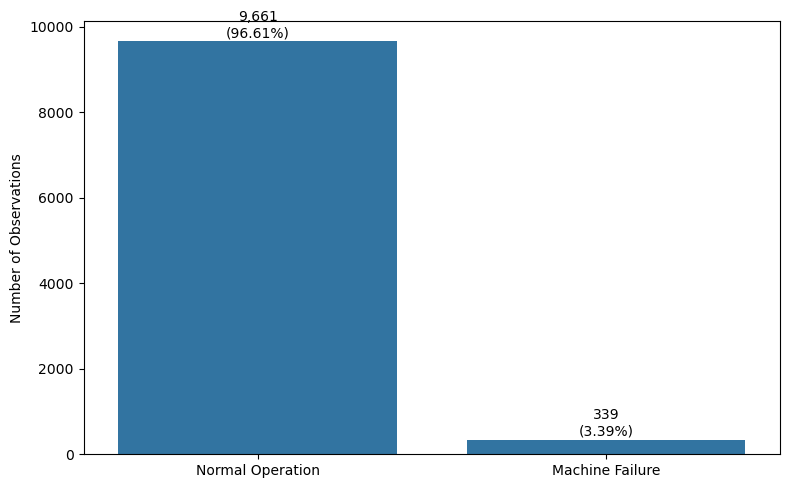

In [12]:
plt.figure(figsize=(8,5))
ax = sns.barplot(
    data = failure_summary,
    x="Status",
    y = "Count"
)

plt.xlabel("")
plt.ylabel("Number of Observations")

for i, row in failure_summary.iterrows():
    ax.text(
        i,
        row["Count"] + 100,
        f'{row["Count"]:,}\n({row["Percentage"]:.2f}%)',
        ha="center"
    )

plt.tight_layout()
plt.show()

Machine failures are relatively rare in the dataset. Only 339 of 10,000 observations (3.39%) represent machine failure, while 96.61% represent normal operating conditions.

This creates a significant class imbalance. A model that simply predicts normal operation for every observation would achieve more than 96% accuracy while failing to identify a single actual machine failure.

Therefore, accuracy alone will not be sufficient for evaluating model performance. Later stages of the analysis will place greater emphasis on metrics such as recall, precision, F1-score, and Precision-Recall AUC.

## Comparison of Operating Conditions by Failure Status

In [13]:
operating_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
comparison = (
    df.groupby("Machine failure")[operating_features].agg(["mean", "median"]).round(2)
)
comparison.T

Machine failure                       0        1
Air temperature [K]     mean     299.97   300.89
                        median   300.00   301.60
Process temperature [K] mean     310.00   310.29
                        median   310.00   310.40
Rotational speed [rpm]  mean    1540.26  1496.49
                        median  1507.00  1365.00
Torque [Nm]             mean      39.63    50.17
                        median    39.90    53.70
Tool wear [min]         mean     106.69   143.78
                        median   107.00   165.00

Initial comparisons show noticeable differences between normal and failed machine observations. Failed machines operate, on average, with substantially higher torque and greater tool wear, while their rotational speed is generally lower.

Temperature differences are smaller at aggregated levels, suggesting that temperature alone may not explain failure risk as strongly as mechanical operating conditions. These relationships will be examined further through visualization and feature engineering.

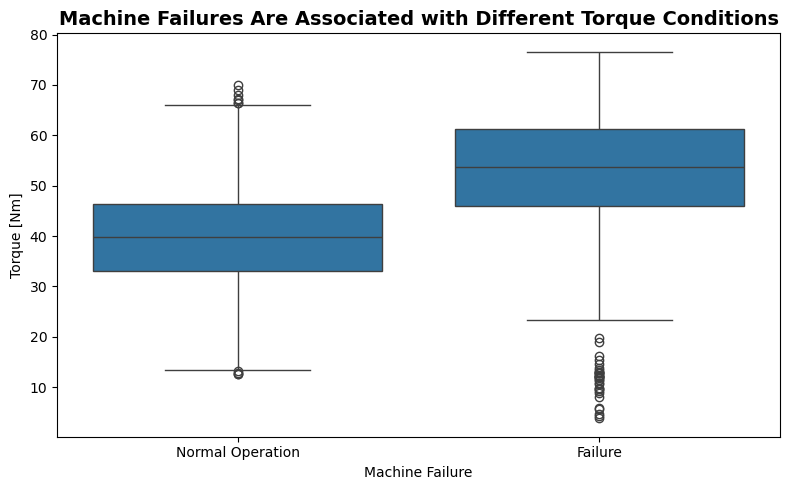

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Torque [Nm]"
)

plt.title(
    "Machine Failures Are Associated with Different Torque Conditions",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Machine Failure")
plt.ylabel("Torque [Nm]")
plt.xticks([0, 1], ["Normal Operation", "Failure"])

plt.tight_layout()
plt.show()

Torque shows a clear relationship with machine failure. Failed observations have an average torque of approximately 50.2 Nm, compared with 39.6 Nm during normal operation.

The distribution also suggests that failure risk is not associated with a single torque value. Instead machines operating under more extreme load conditions appear more frequently among failure observations. This makes torque an important candidate feature for the predictive model.

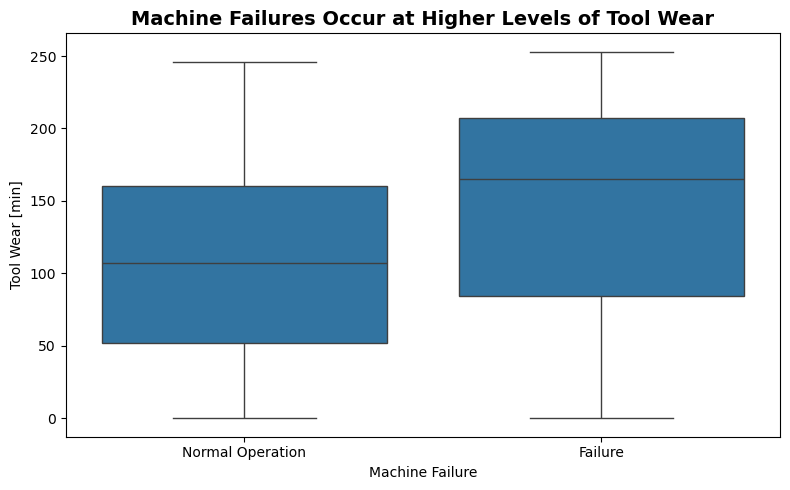

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Tool wear [min]"
)

plt.title(
    "Machine Failures Occur at Higher Levels of Tool Wear",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Machine Failure")
plt.ylabel("Tool Wear [min]")
plt.xticks([0, 1], ["Normal Operation", "Failure"])

plt.tight_layout()
plt.show()

Machine failure observations show considerably greater tool wear. Average tool wear increases from approximately 106.7 minutes during normal operation to 143.8 minutes for failed observations.

The median difference is even more noticeable: approximately 107 minutes for normal operation compared with 165 minutes for machine failures. This suggests that accumulated wear may be an important indicator of increasing equipment risk.

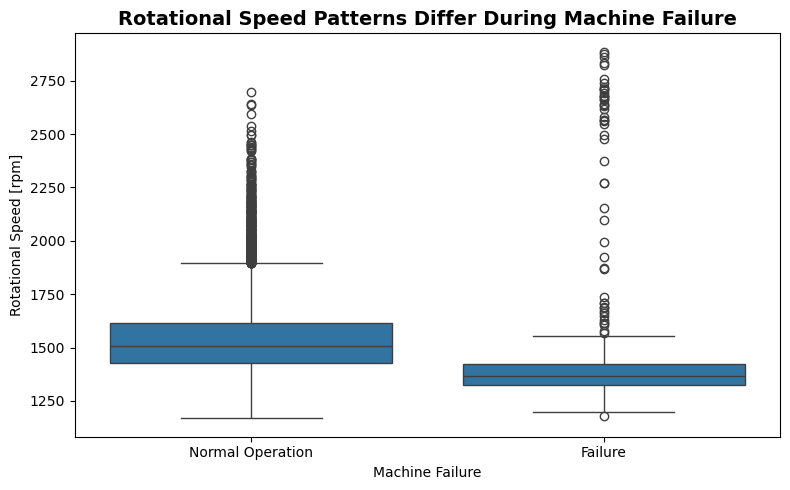

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Rotational speed [rpm]"
)

plt.title(
    "Rotational Speed Patterns Differ During Machine Failure",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Machine Failure")
plt.ylabel("Rotational Speed [rpm]")
plt.xticks([0, 1], ["Normal Operation", "Failure"])

plt.tight_layout()
plt.show()

Failed machines have a lower median rotational speed than machines operating normally. The median rotational speed decreases from approximately 1,507 rpm during normal operation to 1,365 rpm during failure observations.

However, the distribution also contains extreme operating conditions, suggesting that the relationship between rotational speed and failure may be nonlinear. Tree-based models may therefore be useful for capturing these patterns.

In [17]:
type_failure = (
    df.groupby("Type")["Machine failure"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

type_failure["Failure Rate (%)"] = (
    type_failure["mean"] * 100
).round(2)

type_failure

,Type,count,sum,mean,Failure Rate (%)
0,H,1003,21,0.020937,2.09
1,L,6000,235,0.039167,3.92
2,M,2997,83,0.027694,2.77


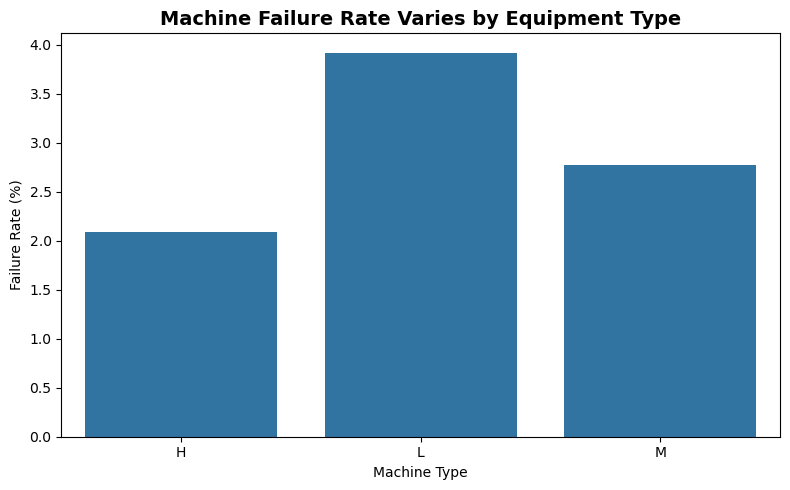

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=type_failure,
    x="Type",
    y="Failure Rate (%)"
)

plt.title(
    "Machine Failure Rate Varies by Equipment Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Machine Type")
plt.ylabel("Failure Rate (%)")

plt.tight_layout()
plt.show()

Failure rates differ across machine types. Type L machines show the highest observed failure rate at approximately 3.92%, followed by Type M at 2.77% and Type H at 2.09%.

Although machine type appears to contain predictive information, these differences should not be interpreted as causal. Other operating conditions may differ across machine types and contribute to the observed failure rates.

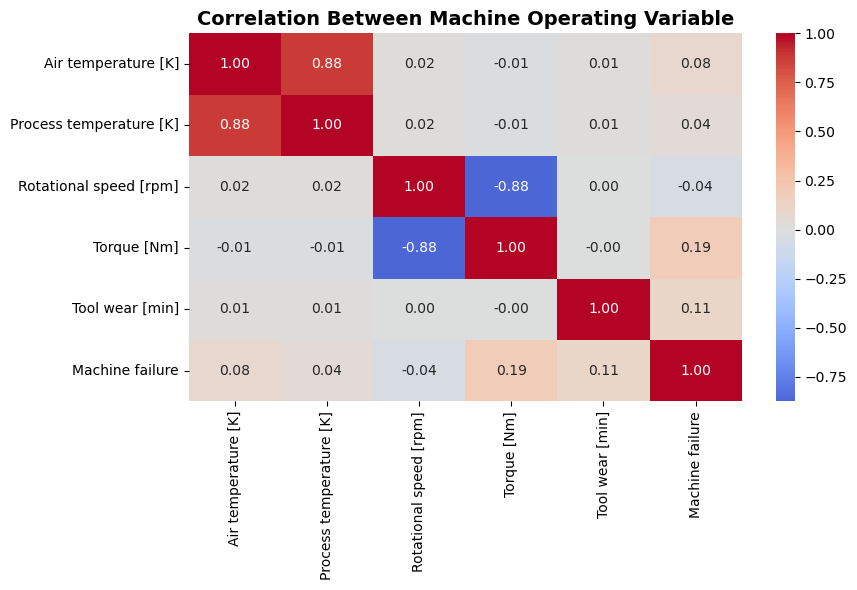

In [19]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

correlation_matrix = df[numeric_features].corr()

plt.figure(figsize = (9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title(
    "Correlation Between Machine Operating Variable",
    fontsize=14,
    fontweight= "bold"
)
plt.tight_layout()
plt.show()

The correlation analysis helps identify relationships among the numerical variables and highlights potential interactions between operating conditions.

However, correlation measures primarily capture linear relationships. Machine failures may result from combinations of operating conditions or nonlinear thresholds, so correlation alone should not be used to determine which features are important.

## EDA Findings

The exploratory analysis identified several operating characteristics associated with machine failure:

- Failed observations generally operate under higher torque.
- Machine failures occur with substantially greater tool wear.
- Failed observations show lower median rotational speed.
- Failure rates vary across different machine types.
- Temperature differences appear less pronounced when considered individually.
- Several relationships appear potentially nonlinear, suggesting that interactions between operating conditions may be important.

These findings provide the basis for the feature-engineering and modeling stages that follow.

## Feature Engineering

In [20]:
df_features = df.copy()

#Temperature difference = process temp - air temp
df_features["Temperature difference [K]"] = (
    df_features["Process temperature [K]"] - df_features["Air temperature [K]"]
)

#From RPM = (ω x 60) / 2π, where ω is in radians per second 
df_features["Angular velocity [rad/s]"] = (
    df_features["Rotational speed [rpm]"] * 2 * np.pi / 60
)

#From P= τ x ω, where τ is torque and ω is angular velocity
df_features["Mechanical power [W]"] = (
    df_features["Torque [Nm]"] * df_features["Angular velocity [rad/s]"]
)

df_features["Tool wear load"] = (
    df_features["Tool wear [min]"] * df_features["Torque [Nm]"]
)

df_features.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Temperature difference [K],Angular velocity [rad/s],Mechanical power [W],Tool wear load
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,10.5,162.420340,6951.590560,0.0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,10.5,147.445415,6826.722724,138.9
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,10.4,156.870193,7749.387543,247.0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,10.4,150.063409,5927.504659,276.5
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,10.5,147.445415,5897.816608,360.0


Feature engineering was used to create additional variables that better represent the physical operating state of the machine.

The engineered features were designed using the relationships between temperature, rotational motion, mechanical load, and tool wear rather than applying arbitrary mathematical transformations.

In [21]:
df_features[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Temperature difference [K]"
    ]
    ].head()

,Air temperature [K],Process temperature [K],Temperature difference [K]
0,298.1,308.6,10.5
1,298.2,308.7,10.5
2,298.1,308.5,10.4
3,298.2,308.6,10.4
4,298.2,308.7,10.5


Temperature difference represents the gap between the machine process temperature and the surrounding air temperature. A change in this relationship may reflect differences in thermal operating conditions or heat dissipation.

In [22]:
df_features[
    [
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Angular velocity [rad/s]",
        "Mechanical power [W]"
    ]
].head()

,Rotational speed [rpm],Torque [Nm],Angular velocity [rad/s],Mechanical power [W]
0,1551,42.8,162.420340,6951.590560
1,1408,46.3,147.445415,6826.722724
2,1498,49.4,156.870193,7749.387543
3,1433,39.5,150.063409,5927.504659
4,1408,40.0,147.445415,5897.816608


Torque and rotational speed describe different aspects of machine operation. Mechanical power combines both measurements into a single feature representing the approximate rate at which rotational mechanical work is being performed.

This feature may help capture operating conditions that are difficult to identify when torque and rotational speed are considered independently.

In [23]:
df_features[
    [
        "Tool wear [min]",
        "Torque [Nm]",
        "Tool wear load"
    ]
].head()

,Tool wear [min],Torque [Nm],Tool wear load
0,0,42.8,0.0
1,3,46.3,138.9
2,5,49.4,247.0
3,7,39.5,276.5
4,9,40.0,360.0


The interaction between tool wear and torque was introduced to represent situations where an increasingly worn tool is simultaneously operating under greater mechanical load.

This feature may help the model identify higher rosk combinations that are not fully represented by tool wear or torque individually.

## Compared Engineered Features by Failure Status

In [24]:
engineered_features = [
    "Temperature difference [K]",
    "Mechanical power [W]",
    "Tool wear load"
]

engineered_comparison = (
    df_features
    .groupby("Machine failure")[engineered_features]
    .agg(["mean", "median"])
    .round(2)
)

engineered_comparison.T

Machine failure                          0        1
Temperature difference [K] mean      10.02     9.40
                           median     9.80     9.30
Mechanical power [W]       mean    6244.55  7282.82
                           median  6243.05  7611.43
Tool wear load             mean    4213.84  7187.94
                           median  3952.80  7681.80

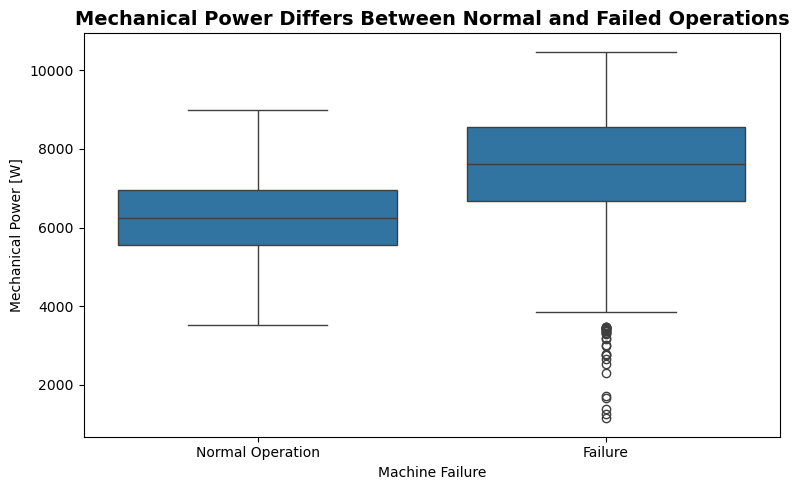

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_features,
    x="Machine failure",
    y="Mechanical power [W]"
)

plt.title(
    "Mechanical Power Differs Between Normal and Failed Operations",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Machine Failure")
plt.ylabel("Mechanical Power [W]")
plt.xticks([0, 1], ["Normal Operation", "Failure"])

plt.tight_layout()
plt.show()

Mechanical power provides a combined view of torque and rotational speed. The distribution shows whether failed machines tend to operate under different power conditions compared with normal observations.

Rather than assuming that the engineered feature is useful, its value will ultimately be tested by comparing model performance with and without the engineered variables.

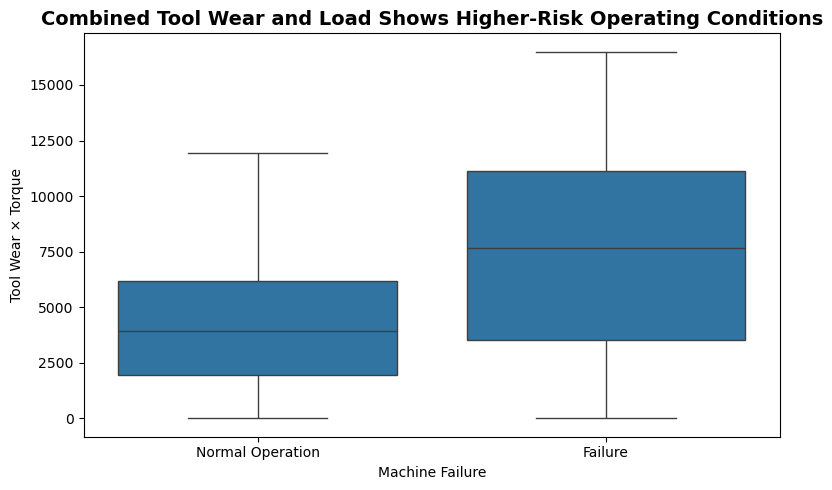

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_features,
    x="Machine failure",
    y="Tool wear load"
)

plt.title(
    "Combined Tool Wear and Load Shows Higher-Risk Operating Conditions",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Machine Failure")
plt.ylabel("Tool Wear × Torque")
plt.xticks([0, 1], ["Normal Operation", "Failure"])

plt.tight_layout()
plt.show()

The interaction between tool wear and torque creates a stronger representation of cumulative wear under mechanical load.

Higher values may indicate operating conditions where equipment has accumulated significant wear while also experiencing greater mechanical stress, making the feature potentially useful for failure prediction.

In [27]:
model_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference [K]",
    "Mechanical power [W]",
    "Tool wear load"
]

target = "Machine failure"

X = df_features[model_features]
y = df_features[target]

X.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature difference [K],Mechanical power [W],Tool wear load
0,M,298.1,308.6,1551,42.8,0,10.5,6951.590560,0.0
1,L,298.2,308.7,1408,46.3,3,10.5,6826.722724,138.9
2,L,298.1,308.5,1498,49.4,5,10.4,7749.387543,247.0
3,L,298.2,308.6,1433,39.5,7,10.4,5927.504659,276.5
4,L,298.2,308.7,1408,40.0,9,10.5,5897.816608,360.0


The final predictor set includes the original operating variables together with the engineered thermal and mechanical features.

Identifiers such as UDI and Product ID are excluded because they do not represent machine operating behavior. The individual failure mode indicators are also excluded because they directly describe failure outcomes and could introduce target leakage.

In [28]:
original_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

engineered_model_features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference [K]",
    "Mechanical power [W]",
    "Tool wear load"
]

## Feature Engineering SUmmary

Three additional operating features were introduced to represent thermal conditions, mechanical power, and the interaction between equipment wear and load.

These features were created using physical and operational reasoning rather than arbitrary transformations. Their usefulness will be evaluated during model development by comparing model performance before and after feature engineering.

In [29]:
feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference [K]",
    "Mechanical power [W]",
    "Tool wear load"
]
x= df_features[feature_columns]
y = df_features["Machine failure"]

print("Feature matrix shape:", X.shape)
print("Target shapre:", y.shape)

Feature matrix shape: (10000, 9)
Target shapre: (10000,)


The predictor matrix contains the machine operating variables and engineered features selected in the previous section. The target variable is Machine failure, where a value of 1 represents failure and 0 represents normal operation.

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations: ", len(X_train))
print("Testing observations: ", len(X_test))

Training observations:  8000
Testing observations:  2000


In [31]:
print("Overall failure rate:")
print(y.mean().round(4))

print("\nTraining failure rate:")
print(y_train.mean().round(4))

print("\nTesting failure rate:")
print(y_test.mean().round(4))

Overall failure rate:
0.0339

Training failure rate:
0.0339

Testing failure rate:
0.034


The dataset was divided into 80% training data and 20% testing data.

A stratified split was used to preserve the proportion of machine failures in both datasets. This is particularly important for an imbalanced classification problem because a random split without stratification could produce an unrepresentative number of failures in either the training or test set.

In [32]:
categorical_features = [
    "Type"
]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference [K]",
    "Mechanical power [W]",
    "Tool wear load"
]

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers = [
        (
            "categorical",
            OneHotEncoder(handle_unknown = "ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

The categorical Type variable is converted using one-hot encoding so that machine type can be used by the machine learning algorithms without implying an artificial numerical ranking.

Numerical features are standardized to a common scale. This is particularly important for models such as Logistic Regression, where large differences in feature magnitude can affect model fitting.

The preprocessing steps are defined within a reusable pipeline so that the same transformations can later be applied consistently to both training data and new observations.

## Confirm Class Distribution

In [34]:
train_distribution = y_train.value_counts().sort_index()
print("Training set")
print(train_distribution)

print("\nFailure percentage:")
print((y_train.mean() * 100).round(2), "%")

Training set
Machine failure
0    7729
1     271
Name: count, dtype: int64

Failure percentage:
3.39 %


## Evaluation Metrics

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

Because machine failures represent only a small proportion of the dataset, model performance will not be assessed using accuracy alone.

Greater emphasis will be placed on recall, precision, F1-score, ROC-AUC, and Precision-Recall AUC. Recall is particularly important because it measures the proportion of actual failures successfully identified by the model, while Precision-Recall AUC provides a more informative view of performance when the positive class is rare.

## Model Evaluation Function

In [36]:
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division = 0),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    }

    return results

## Model Evaluation and Metrics Summary

The dataset was divided into stratified training and test sets to preserve the original failure distribution.

A preprocessing pipeline was established to encode machine type and standardize numerical features while preventing information from the test data from influencing model training.

A consistent evaluation framework was also defined so that all models can be compared using the same performance metrics.

## Baseline Modeling and Logistic Regression

## Naive Baseline Model

In [37]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

baseline_model = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]
)

baseline_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
baseline_results = evaluate_model(
    baseline_model,
    X_test,
    y_test
)

baseline_results

{'Accuracy': 0.966,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1 Score': 0.0,
 'ROC-AUC': 0.5,
 'PR-AUC': 0.034}

A naïve baseline model was created by predicting the majority class for every observation.

Because normal machine operation represents approximately 96.6% of the dataset, this approach achieves high accuracy despite failing to identify any actual machine failures.

This confirms that overall accuracy is not an appropriate standalone metric for this predictive maintenance problem.

## Baseline Confusion Matrix

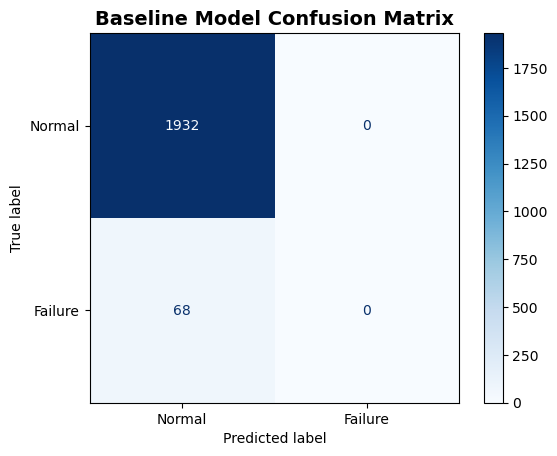

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    baseline_model,
    X_test,
    y_test,
    display_labels = ["Normal", "Failure"],
    cmap="Blues"
)

plt.title("Baseline Model Confusion Matrix",
          fontsize=14,
          fontweight="bold"
)

plt.show()

## Logistic Regression

In [40]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)
logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Logistic Regression Model Evaluation

In [41]:
logistics_results = evaluate_model(
    logistic_model,
    X_test,
    y_test
)
logistics_results

{'Accuracy': 0.9675,
 'Precision': 0.5714285714285714,
 'Recall': 0.17647058823529413,
 'F1 Score': 0.2696629213483146,
 'ROC-AUC': 0.9255038972110583,
 'PR-AUC': 0.46380544310923355}

In [42]:
##Classification report

logistic_predictions = logistic_model.predict(X_test)

print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names = ["Normal Operation", "Machine Failure"]
    )
)

                  precision    recall  f1-score   support

Normal Operation       0.97      1.00      0.98      1932
 Machine Failure       0.57      0.18      0.27        68

        accuracy                           0.97      2000
       macro avg       0.77      0.59      0.63      2000
    weighted avg       0.96      0.97      0.96      2000



Logistic Regression was selected as the first supervised learning model because it provides a simple and interpretable benchmark for binary classification.

Unlike the naïve baseline, the model uses machine operating conditions to estimate the probability of failure. Its performance will be compared against more complex nonlinear models later in the analysis.

## Logistic Regression Confusion Matrix

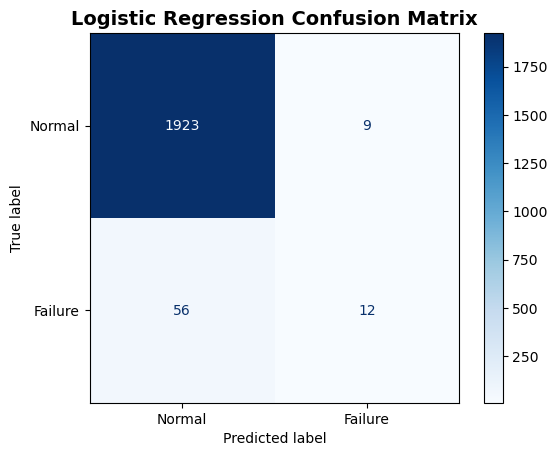

In [43]:
ConfusionMatrixDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    display_labels = ["Normal", "Failure"],
    cmap = "Blues"
)

plt.title(
    "Logistic Regression Confusion Matrix",
    fontsize = 14,
    fontweight="bold"
)

plt.show()

## Comparison: Baseline V/S Logistic Regression

In [44]:
model_results = pd.DataFrame(
    [
        {"Model": "Naive Baseline", **baseline_results},
        {"Model": "Logistic Baseline", **logistics_results}
    ]
)
model_results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Naive Baseline,0.966,0.000,0.000,0.00,0.500,0.034
1,Logistic Baseline,0.968,0.571,0.176,0.27,0.926,0.464


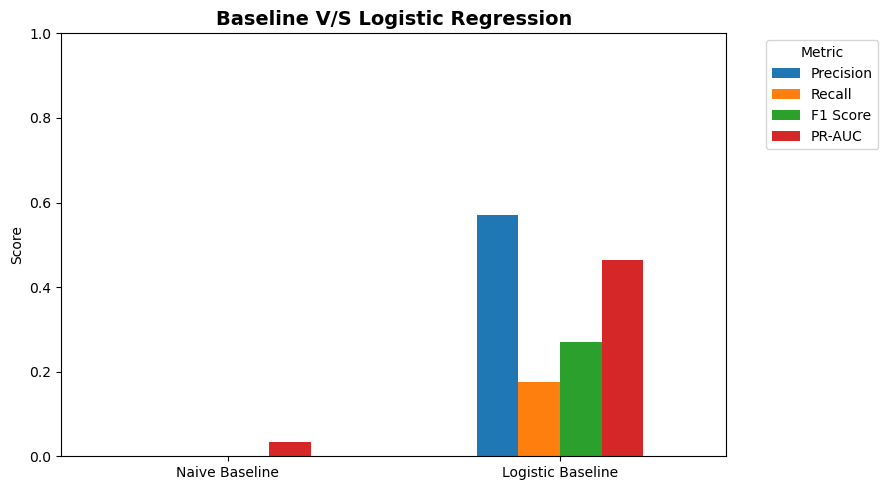

In [45]:
comparison_plot = (
    model_results[
        [
            "Model",
            "Precision",
            "Recall",
            "F1 Score",
            "PR-AUC"
        ]
    ]
    .set_index("Model")
)

comparison_plot.plot(
    kind="bar",
    figsize= (9, 5)
)

plt.title(
    "Baseline V/S Logistic Regression",
    fontsize = 14,
    fontweight="bold"
)

plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=0)
plt.ylim(0, 1)

plt.legend(
    title = "Metric",
    bbox_to_anchor = (1.05, 1),
    loc = "upper left"
)

plt.tight_layout()
plt.show()

## Baseline Modeling and Logistic Regression Summary

The baseline experiment demonstrated that high classification accuracy can be achieved without detecting any machine failures, confirming the need for more appropriate evaluation metrics.

Logistic Regression provided the first meaningful predictive benchmark. Introducing balanced class weights allows the model to place greater emphasis on detecting the minority failure class, creating a tradeoff between failure recall and false alarms.

This tradeoff will become increasingly important when comparing more advanced models and selecting an operational decision threshold.

## First Class Imbalance Experiment (Balanced Logistic Model)

In [46]:
balanced_logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

balanced_logistic_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Model Evaluation

In [47]:
balanced_logistic_results = evaluate_model(
    balanced_logistic_model,
    X_test,
    y_test
)

balanced_logistic_results

{'Accuracy': 0.8585,
 'Precision': 0.1791044776119403,
 'Recall': 0.8823529411764706,
 'F1 Score': 0.2977667493796526,
 'ROC-AUC': 0.9385047497259774,
 'PR-AUC': 0.4297030345248936}

In [48]:
model_results = pd.DataFrame(
    [
        {"Model": "Naive Baseline", **baseline_results},
        {"Model": "Logistic Regression", **logistics_results},
        {
            "Model": "Balanced Logistic Regression",
            **balanced_logistic_results
        }
    ]
)

model_results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Naive Baseline,0.966,0.000,0.000,0.000,0.500,0.034
1,Logistic Regression,0.968,0.571,0.176,0.270,0.926,0.464
2,Balanced Logistic Regression,0.858,0.179,0.882,0.298,0.939,0.430


## Standard Random Forest (Non-linear Model) Training

In [49]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators = 300,
                random_state = 42,
                n_jobs = -1
            )
        )
    ]
)
random_forest_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Random Forest was selected as the next model because it can capture nonlinear relationships and interactions between machine operating variables.

Unlike Logistic Regression, Random Forest does not assume that the relationship between each feature and machine failure is linear.

## Model Evaluation

In [50]:
random_forest_results = evaluate_model(
    random_forest_model,
    X_test,
    y_test
)
random_forest_results

{'Accuracy': 0.9925,
 'Precision': 0.9649122807017544,
 'Recall': 0.8088235294117647,
 'F1 Score': 0.88,
 'ROC-AUC': 0.9728869808793084,
 'PR-AUC': 0.8910770907946162}

In [51]:
random_forest_predictions = random_forest_model.predict(X_test)

print(
    classification_report(
        y_test,
        random_forest_predictions,
        target_names = ["Normal Operation", "Machine Failure"]
    )
)

                  precision    recall  f1-score   support

Normal Operation       0.99      1.00      1.00      1932
 Machine Failure       0.96      0.81      0.88        68

        accuracy                           0.99      2000
       macro avg       0.98      0.90      0.94      2000
    weighted avg       0.99      0.99      0.99      2000



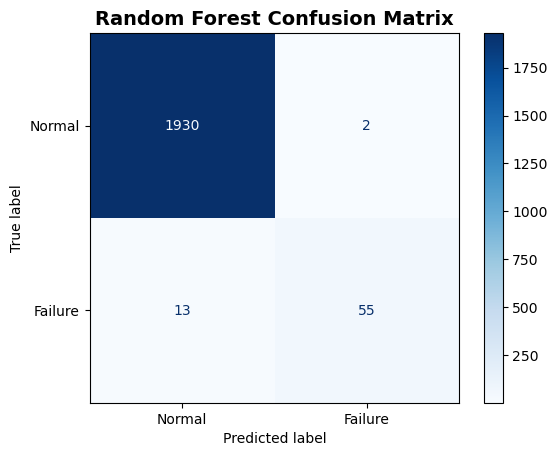

In [52]:
# Confusion Matrix

ConfusionMatrixDisplay.from_estimator(
    random_forest_model,
    X_test,
    y_test,
    display_labels = ["Normal", "Failure"],
    cmap = "Blues"
)

plt.title(
    "Random Forest Confusion Matrix",
    fontsize = 14,
    fontweight="bold"
)
plt.show()

The Random Forest model improves the ability to capture nonlinear relationships between machine operating conditions.

The confusion matrix is especially important for evaluating how many actual machine failures are correctly identified and how many are missed. Because the dataset is highly imbalanced, the balance between failure recall and false-positive predictions is more informative than overall accuracy alone.

## Balanced Random Forest

In [53]:
balanced_random_forest = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators = 300,
                class_weight = "balanced",
                random_state = 42,
                n_jobs = -1
            )
        )
    ]
)

balanced_random_forest.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Model Evaluation

In [54]:
balanced_rf_results = evaluate_model(
    balanced_random_forest,
    X_test,
    y_test
)
balanced_rf_results

{'Accuracy': 0.9895,
 'Precision': 0.9607843137254902,
 'Recall': 0.7205882352941176,
 'F1 Score': 0.8235294117647058,
 'ROC-AUC': 0.9714026915113873,
 'PR-AUC': 0.872813533207478}

## Comparison: Standard V/S Balanced Random Forest 

In [55]:
rf_comparison = pd.DataFrame(
    [
        {
            "Model": "Random Forest",
            **random_forest_results
        },
        {
            "Model": "Balanced Random Forest",
            **balanced_rf_results
        }
    ]
)
rf_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Random Forest,0.992,0.965,0.809,0.880,0.973,0.891
1,Balanced Random Forest,0.990,0.961,0.721,0.824,0.971,0.873


In [56]:
model_results = pd.DataFrame(
    [
        {"Model": "Naive Baseline", **baseline_results},
        {"Model": "Logistic Regression", **logistics_results},
        {
            "Model": "Balanced Logistic Regression",
            **balanced_logistic_results
        },
        {
            "Model": "Random Forest",
            **random_forest_results
        },
        {
            "Model": "Balanced Random Forest",
            **balanced_rf_results
        }
    ]
)

model_results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Naive Baseline,0.966,0.000,0.000,0.000,0.500,0.034
1,Logistic Regression,0.968,0.571,0.176,0.270,0.926,0.464
2,Balanced Logistic Regression,0.858,0.179,0.882,0.298,0.939,0.430
3,Random Forest,0.992,0.965,0.809,0.880,0.973,0.891
4,Balanced Random Forest,0.990,0.961,0.721,0.824,0.971,0.873


## Model Comparison Summary

The model comparison shows a substantial difference in performance across the algorithms. The naïve baseline achieves 96.6% accuracy while failing to identify any machine failures, demonstrating why accuracy alone is misleading for this dataset.

Balancing the Logistic Regression model substantially increased failure recall from 17.6% to 88.2%, but this improvement came at the cost of considerably lower precision. In contrast, the standard Random Forest achieved the strongest overall performance, with 96.5% precision, 80.9% recall, an F1-score of 88.0%, and a PR-AUC of 0.891.

Interestingly, applying balanced class weights did not improve the Random Forest model. This demonstrates that imbalance-handling techniques should be evaluated experimentally rather than assumed to improve every algorithm.

## Standard XGBoost

In [57]:
from xgboost import XGBClassifier

In [58]:
xgboost_model = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        (
            "classifier", 
            XGBClassifier(
                n_estimators = 300,
                learning_rate = 0.05,
                max_depth = 4,
                subsample = 0.8,
                colsample_bytree = 0.8,
                objective = "binary:logistic",
                eval_metric = "logloss",
                random_state = 42
            )
        )
    ]
)

xgboost_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


XGBoost was evaluated as a gradient-boosting model capable of learning complex nonlinear relationships between machine operating conditions.

Unlike Random Forest, which builds many independent trees, XGBoost builds trees sequentially so that each new tree focuses on correcting errors made by the previous trees.

## Model Evaluation

In [59]:
xgboost_results = evaluate_model(
    xgboost_model,
    X_test,
    y_test
)
xgboost_results

{'Accuracy': 0.99,
 'Precision': 0.9137931034482759,
 'Recall': 0.7794117647058824,
 'F1 Score': 0.8412698412698413,
 'ROC-AUC': 0.9861466325660699,
 'PR-AUC': 0.8909710432640855}

In [60]:
xgboost_predictions = xgboost_model.predict(X_test)
print(
    classification_report(
        y_test,
        xgboost_predictions,
        target_names = ["Normal Operation", "Machine Failure"]
    )
)

                  precision    recall  f1-score   support

Normal Operation       0.99      1.00      0.99      1932
 Machine Failure       0.91      0.78      0.84        68

        accuracy                           0.99      2000
       macro avg       0.95      0.89      0.92      2000
    weighted avg       0.99      0.99      0.99      2000



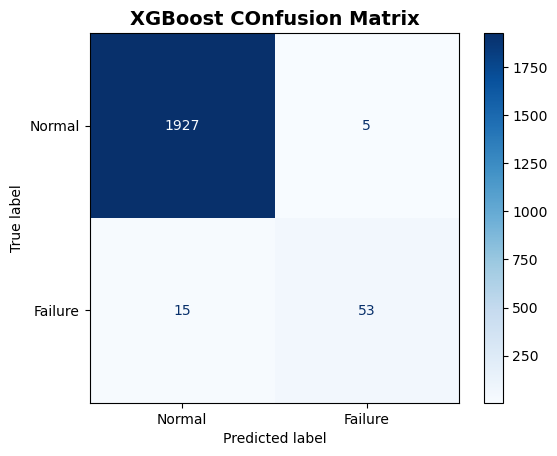

In [61]:
## Confusion Matrix

ConfusionMatrixDisplay.from_estimator(
    xgboost_model,
    X_test,
    y_test,
    display_labels = ["Normal", "Failure"],
    cmap = "Blues"
    )

plt.title(
    "XGBoost COnfusion Matrix",
    fontsize = 14,
    fontweight = "bold"
)
plt.show()

The XGBoost confusion matrix provides a direct view of how effectively the model identifies actual machine failures while controlling false-positive predictions.

The result will be compared with Random Forest to determine whether gradient boosting provides a meaningful improvement in failure detection.

## Class Imbalance Handling using scale_pos_weight

In [62]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Scale POS weight:", round(scale_pos_weight, 2))

Scale POS weight: 28.52


## Balanced XGBoost

In [63]:
balanced_xgboost_model = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        (
            "classifier", 
            XGBClassifier(
                n_estimators = 300,
                learning_rate = 0.05,
                max_depth = 4,
                subsample = 0.8,
                colsample_bytree = 0.8,
                scale_pos_weight = scale_pos_weight,
                objective = "binary:logistic",
                eval_metric = "logloss",
                random_state =42
            )
        )
    ]
)

balanced_xgboost_model.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [64]:
balanced_xgboost_results= evaluate_model(
    balanced_xgboost_model,
    X_test,
    y_test
)

balanced_xgboost_results

{'Accuracy': 0.988,
 'Precision': 0.8055555555555556,
 'Recall': 0.8529411764705882,
 'F1 Score': 0.8285714285714286,
 'ROC-AUC': 0.9827441846303738,
 'PR-AUC': 0.8872712462331763}

## Model Comparison: Standard V/S Balanced XGBoost

In [65]:
xgb_comparison = pd.DataFrame(
    [
        {
            "Model": "XGBoost",
            **xgboost_results
        },
        {
            "Model": "Balanced XGBoost",
            **balanced_xgboost_results
        }
    ]
)

xgb_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,XGBoost,0.990,0.914,0.779,0.841,0.986,0.891
1,Balanced XGBoost,0.988,0.806,0.853,0.829,0.983,0.887


## Adding XGBoost to Main Model Comparison

In [66]:
model_results = pd.DataFrame(
    [
        {"Model": "Naive Baseline", **baseline_results},
        {"Model": "Logistic Regression", **logistics_results},
        {
            "Model": "Balanced Logistic Regression",
            **balanced_logistic_results
        },
        {
            "Model": "Random Forest",
            **random_forest_results
        },
        {
            "Model": "Balanced Random Forest",
            **balanced_rf_results
        },
        {
            "Model": "XGBoost",
            **xgboost_results
        },
        {
            "Model": "Balanced XGBoost",
            **balanced_xgboost_results
        }
    ]
)

model_results[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ]
].round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Naive Baseline,0.966,0.000,0.000,0.000,0.500,0.034
1,Logistic Regression,0.968,0.571,0.176,0.270,0.926,0.464
2,Balanced Logistic Regression,0.858,0.179,0.882,0.298,0.939,0.430
3,Random Forest,0.992,0.965,0.809,0.880,0.973,0.891
4,Balanced Random Forest,0.990,0.961,0.721,0.824,0.971,0.873
5,XGBoost,0.990,0.914,0.779,0.841,0.986,0.891
6,Balanced XGBoost,0.988,0.806,0.853,0.829,0.983,0.887


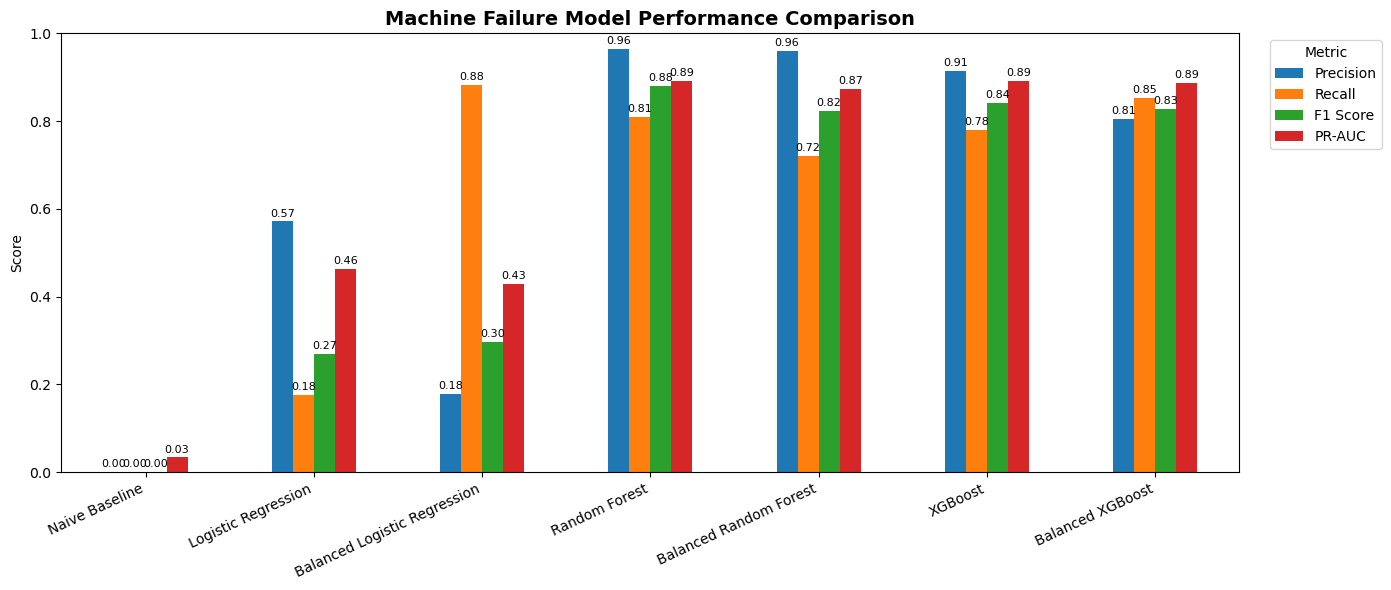

In [67]:
comparison_plot = (
    model_results[
        [
            "Model",
            "Precision",
            "Recall",
            "F1 Score",
            "PR-AUC"
        ]
    ]
    .set_index("Model")
)

ax = comparison_plot.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title(
    "Machine Failure Model Performance Comparison",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=2,
        fontsize=8
    )

plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

XGBoost demonstrated strong predictive performance, achieving a ROC-AUC of 0.986 and a PR-AUC of 0.891. Although its default classification threshold produced slightly lower precision, recall, and F1-score than Random Forest, its strong ROC-AUC indicates excellent ability to distinguish between normal and failure observations across probability thresholds.

Applying class weighting to XGBoost increased failure recall from 77.9% to 85.3%, but reduced precision from 91.4% to 80.6%. This demonstrates the operational tradeoff between identifying additional failures and generating additional false alarms.

Among the models evaluated so far, Random Forest provides the strongest overall balance at the default classification threshold, achieving 96.5% precision, 80.9% recall, and an F1-score of 88.0%. However, XGBoost's strong ranking performance makes it an important candidate for probability-threshold optimization before a final model is selected.

Feature importance from XGBoost also showed that rotational speed was the strongest individual predictor, while engineered variables including tool-wear load, mechanical power, and temperature difference ranked among the most influential features. This suggests that combining raw sensor measurements into operationally meaningful features can provide additional predictive information.

## Feature Importance Determination (XGBoost)

In [68]:
xgb_classifier = xgboost_model.named_steps["classifier"]

xgb_preprocessor = xgboost_model.named_steps["preprocessor"]

xgb_feature_names = (
    xgb_preprocessor
    .get_feature_names_out()
)

In [69]:
xgb_feature_importance = pd.DataFrame(
    {
        "Feature": xgb_feature_names,
        "Importance": xgb_classifier.feature_importances_
    }
)

xgb_feature_importance["Feature"] = (
    xgb_feature_importance["Feature"]
    .str.replace("numerical__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)

xgb_feature_importance = (
    xgb_feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
)

xgb_feature_importance.head(10)

,Feature,Importance
5,Rotational speed [rpm],0.180515
10,Tool wear load,0.155482
9,Mechanical power [W],0.144473
8,Temperature difference [K],0.129957
6,Torque [Nm],0.114615
7,Tool wear [min],0.089410
2,Type_M,0.055113
1,Type_L,0.048966
3,Air temperature [K],0.032494
4,Process temperature [K],0.025095


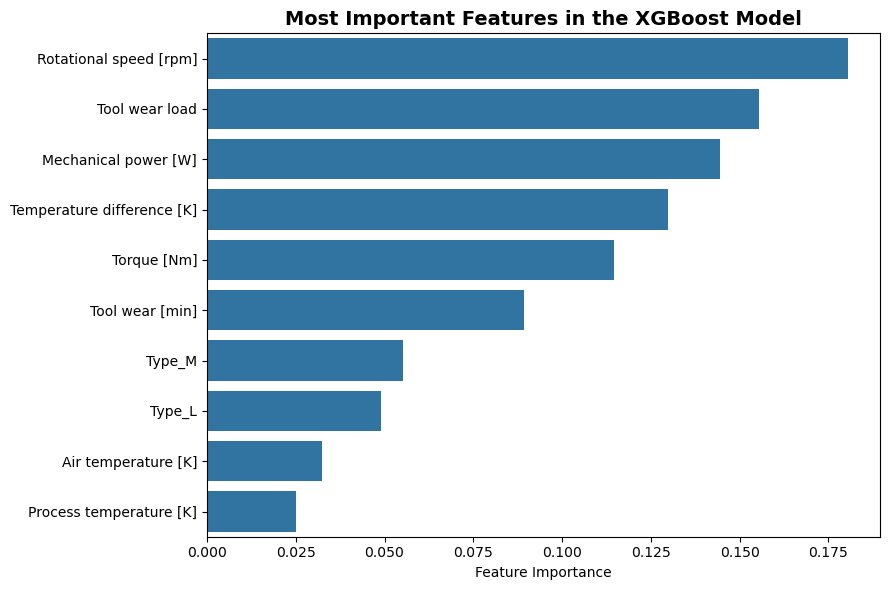

In [70]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=xgb_feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title(
    "Most Important Features in the XGBoost Model",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("")

plt.tight_layout()
plt.show()

## Model Selection and Threshold Optimization

In [71]:
# Getting Predicted probabilities to estimate failure risk

rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]
xgb_probabilities = xgboost_model.predict_proba(X_test)[:, 1]

## Threshold Evaluation

In [82]:
def evaluate_thresholds(y_true, probabilities, thresholds):
    results = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        results.append({
            "Threshold": threshold,
            "Precision": precision_score(
                y_true,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_true,
                predictions,
                zero_division=0
            ),
            "F1 Score": f1_score(
                y_true,
                predictions,
                zero_division=0
            )
        })

    return pd.DataFrame(results)

In [83]:
thresholds = np.arange(0.10, 0.91, 0.05)

## RF Threshold Ananlysis

In [84]:
rf_threshold_results = evaluate_thresholds(
    y_test,
    rf_probabilities,
    thresholds
)

# Check the table
display(rf_threshold_results)

,Threshold,Precision,Recall,F1 Score
0,0.10,0.551402,0.867647,0.674286
1,0.15,0.702381,0.867647,0.776316
2,0.20,0.786667,0.867647,0.825175
3,0.25,0.850746,0.838235,0.844444
4,0.30,0.903226,0.823529,0.861538
5,0.35,0.949153,0.823529,0.881890
6,0.40,0.965517,0.823529,0.888889
7,0.45,0.965517,0.823529,0.888889
8,0.50,0.964912,0.808824,0.880000
9,0.55,0.964912,0.808824,0.880000


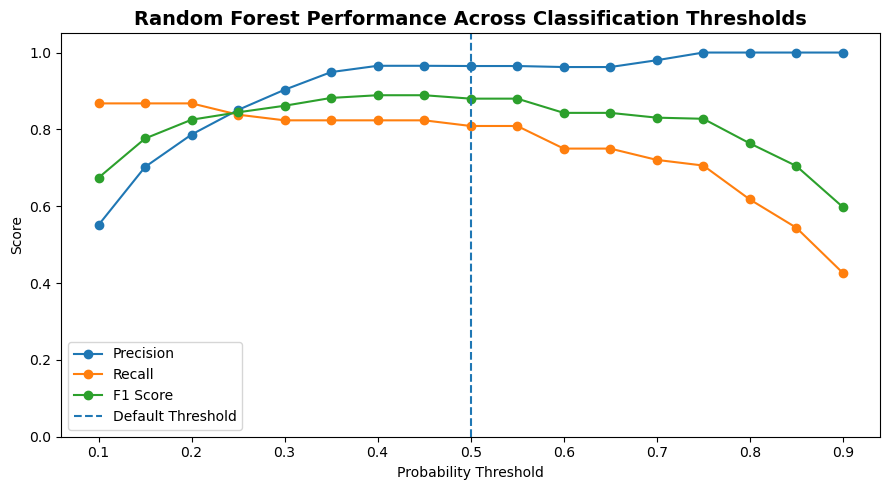

In [85]:
plt.figure(figsize=(9, 5))

plt.plot(
    rf_threshold_results["Threshold"],
    rf_threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    rf_threshold_results["Threshold"],
    rf_threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    rf_threshold_results["Threshold"],
    rf_threshold_results["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Default Threshold"
)

plt.title(
    "Random Forest Performance Across Classification Thresholds",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.legend()
plt.tight_layout()
plt.show()

The Random Forest threshold analysis shows the expected tradeoff between precision and recall. Lower thresholds identify a greater proportion of machine failures, but they also increase the number of false-positive alerts. As the threshold increases, precision improves while recall gradually declines.

The default threshold of 0.50 provides very high precision with strong recall, while thresholds around 0.25–0.40 offer a more balanced performance and slightly higher F1-scores. This suggests that the final threshold should be selected based on the operational priority: minimizing false alarms or detecting as many failures as possible.

In [86]:
print(rf_threshold_results.columns)

Index(['Threshold', 'Precision', 'Recall', 'F1 Score'], dtype='object')


## XGBoost Threshold Analysis

In [90]:
xgb_threshold_results = evaluate_thresholds(
    y_test,
    xgb_probabilities,
    thresholds
)

xgb_threshold_results.round(3)

,Threshold,Precision,Recall,F1 Score
0,0.10,0.663,0.868,0.752
1,0.15,0.781,0.838,0.809
2,0.20,0.814,0.838,0.826
3,0.25,0.877,0.838,0.857
4,0.30,0.889,0.824,0.855
5,0.35,0.903,0.824,0.862
6,0.40,0.918,0.824,0.868
7,0.45,0.915,0.794,0.850
8,0.50,0.914,0.779,0.841
9,0.55,0.914,0.779,0.841


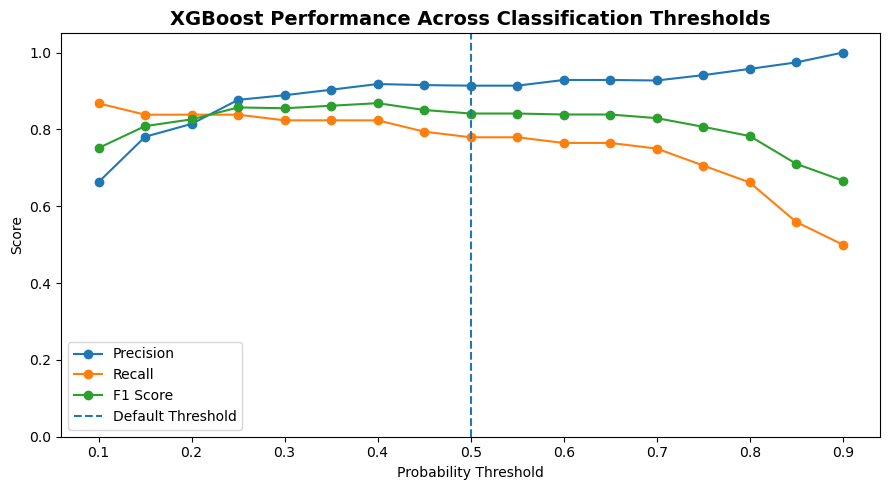

In [91]:
plt.figure(figsize=(9, 5))

plt.plot(
    xgb_threshold_results["Threshold"],
    xgb_threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    xgb_threshold_results["Threshold"],
    xgb_threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    xgb_threshold_results["Threshold"],
    xgb_threshold_results["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.axvline(
    x=0.50,
    linestyle="--",
    label="Default Threshold"
)

plt.title(
    "XGBoost Performance Across Classification Thresholds",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.legend()
plt.tight_layout()
plt.show()

The XGBoost threshold analysis shows a stable tradeoff between precision and recall across a broad range of decision thresholds. Lower thresholds improve failure detection by increasing recall, while higher thresholds improve precision by reducing false-positive alerts.

The strongest balance appears around the 0.25–0.40 range, where precision, recall, and F1-score remain relatively close. At the default threshold of 0.50, the model maintains high precision but misses a larger proportion of failures.

Compared with the default threshold, a lower threshold may therefore provide a more practical operating point when the cost of missing a machine failure is greater than the cost of investigating an additional maintenance alert.

## Best F1 Threshold

In [88]:
## RF Model

rf_best_f1 = rf_threshold_results.loc[
    rf_threshold_results["F1 Score"].idxmax()
    ]
rf_best_f1

Threshold    0.400000
Precision    0.965517
Recall       0.823529
F1 Score     0.888889
Name: 6, dtype: float64

In [92]:
## XGBoost Model
xgb_best_f1 = xgb_threshold_results.loc[
    xgb_threshold_results["F1 Score"].idxmax()
]

xgb_best_f1

Threshold    0.400000
Precision    0.918033
Recall       0.823529
F1 Score     0.868217
Name: 6, dtype: float64

In [93]:
best_threshold_comparison = pd.DataFrame(
    [
        {
            "Model": "Random Forest",
            **rf_best_f1.to_dict()
        },
        {
            "Model": "XGBoost",
            **xgb_best_f1.to_dict()
        }
    ]
)

best_threshold_comparison.round(3)

,Model,Threshold,Precision,Recall,F1 Score
0,Random Forest,0.4,0.966,0.824,0.889
1,XGBoost,0.4,0.918,0.824,0.868


## Business Oriented Threshold Selection

Purpose: Finetune metrics to align operational goal of detecting at least 85% of failures

In [96]:
# RF Model

rf_high_recall = rf_threshold_results[
    rf_threshold_results["Recall"] >= 0.85
].sort_values(
    "Precision",
    ascending=False
)

rf_high_recall.head()

,Threshold,Precision,Recall,F1 Score
2,0.20,0.786667,0.867647,0.825175
1,0.15,0.702381,0.867647,0.776316
0,0.10,0.551402,0.867647,0.674286


In [95]:
# XGBoost Model

xgb_high_recall = xgb_threshold_results[
    xgb_threshold_results["Recall"] >= 0.85
].sort_values(
    "Precision",
    ascending=False
)

xgb_high_recall.head()

,Threshold,Precision,Recall,F1 Score
0,0.1,0.662921,0.867647,0.751592


When a minimum failure recall of 85% was required, Random Forest provided the strongest operating point. At a probability threshold of 0.20, the model achieved 86.8% recall while maintaining 78.7% precision and an F1-score of 82.5%.

XGBoost achieved the same 86.8% recall at a threshold of 0.10, but precision decreased to 66.3%. Random Forest therefore identified the same proportion of machine failures while generating fewer false-positive maintenance alerts.

However, lowering the Random Forest threshold from the default 0.50 to 0.20 introduces a tradeoff. The default threshold provides substantially higher precision and a higher overall F1-score, while the lower threshold detects a greater proportion of failures. The appropriate operating threshold would therefore depend on the relative cost of missed failures and unnecessary maintenance inspections.

## Precision-Recall Curve

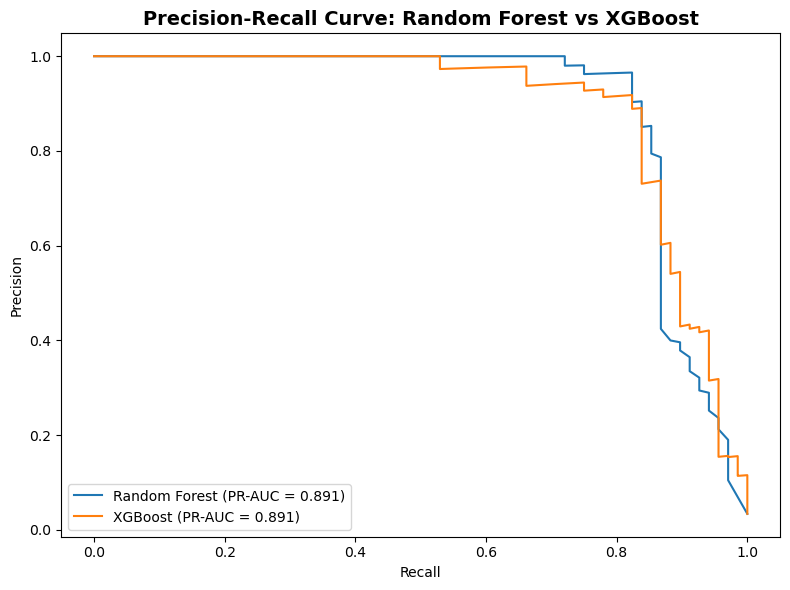

In [98]:
from sklearn.metrics import precision_recall_curve

rf_precision, rf_recall, _ = precision_recall_curve(
    y_test,
    rf_probabilities
)

xgb_precision, xgb_recall, _ = precision_recall_curve(
    y_test,
    xgb_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_recall,
    rf_precision,
    label=f"Random Forest (PR-AUC = {random_forest_results['PR-AUC']:.3f})"
)
plt.plot(
    xgb_recall,
    xgb_precision,
    label=f"XGBoost (PR-AUC = {xgboost_results['PR-AUC']:.3f})"
)
plt.title(
    "Precision-Recall Curve: Random Forest vs XGBoost",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.tight_layout()
plt.show()

The Precision-Recall curves show that Random Forest and XGBoost provide nearly identical overall performance, with both models achieving a PR-AUC of approximately 0.891.

Although their overall ranking performance is similar, Random Forest maintains slightly stronger precision across much of the moderate to high recall range. This aligns with the threshold analysis, where Random Forest achieved the required failure recall with fewer false-positive predictions than XGBoost.

The result suggests that model selection should not rely on PR-AUC alone. The operating threshold and the corresponding precision-recall tradeoff are equally important when choosing a model for predictive maintenance.

## Model Selection Approach

Based on the model comparison and threshold analysis, Random Forest was selected as the leading model for this project.

At the default threshold of 0.50, Random Forest achieved the strongest overall balance of precision, recall, and F1-score. When the business requirement was changed to prioritize failure detection with recall of at least 85%, Random Forest also outperformed XGBoost by achieving the same recall with higher precision and fewer false-positive alerts.

Although XGBoost achieved the highest ROC-AUC and matched Random Forest on PR-AUC, Random Forest provided the better operational tradeoff across the evaluated thresholds.

For this reason, Random Forest was selected as the final model, while the classification threshold remains a business decision that can be adjusted depending on whether the priority is minimizing false alarms or detecting a greater proportion of machine failures.

## Model Explainability and Business Interpretation

In [100]:
##Random Forest Feature Importance and Priority

rf_classifier = random_forest_model.named_steps["classifier"]
rf_preprocessor = random_forest_model.named_steps["preprocessor"]

rf_feature_names = rf_preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_classifier.feature_importances_
})

rf_importance["Feature"] = (
    rf_importance["Feature"]
    .str.replace("numerical__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)

rf_importance = (
    rf_importance
    .sort_values("Importance", ascending=False)
)

rf_importance.head(10)

,Feature,Importance
9,Mechanical power [W],0.211847
10,Tool wear load,0.211301
5,Rotational speed [rpm],0.159159
6,Torque [Nm],0.132234
8,Temperature difference [K],0.117112
7,Tool wear [min],0.060951
3,Air temperature [K],0.039017
4,Process temperature [K],0.032678
1,Type_L,0.018294
2,Type_M,0.011447


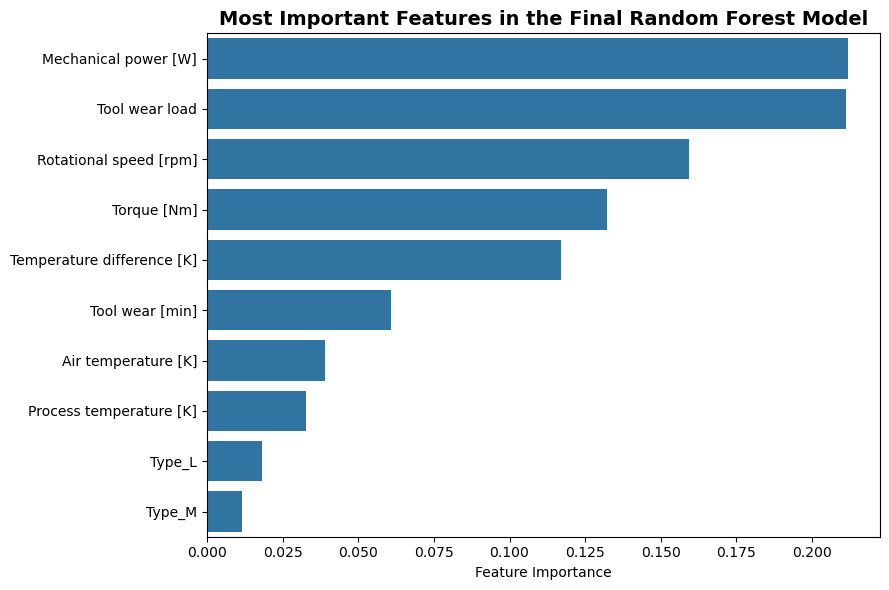

In [101]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=rf_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title(
    "Most Important Features in the Final Random Forest Model",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("")

plt.tight_layout()
plt.show()

The final Random Forest model relies most heavily on a combination of mechanical load, rotational behavior, thermal conditions, and tool wear.

Several engineered variables also appear among the most influential predictors, suggesting that combinations of raw sensor measurements provide additional information beyond the original variables alone.

These importance values describe predictive contribution rather than causation. A feature may help the model distinguish between normal and failure observations without directly causing the underlying equipment failure.

## Permutation Importance

In [102]:
from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="f1"
)

In [103]:
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": permutation_results.importances_mean
}).sort_values(
    "Importance",
    ascending=False
)

permutation_df

,Feature,Importance
3,Rotational speed [rpm],0.337314
6,Temperature difference [K],0.327404
8,Tool wear load,0.231785
7,Mechanical power [W],0.186424
0,Type,0.060651
5,Tool wear [min],0.011609
4,Torque [Nm],0.009032
1,Air temperature [K],0.004385
2,Process temperature [K],-0.001359


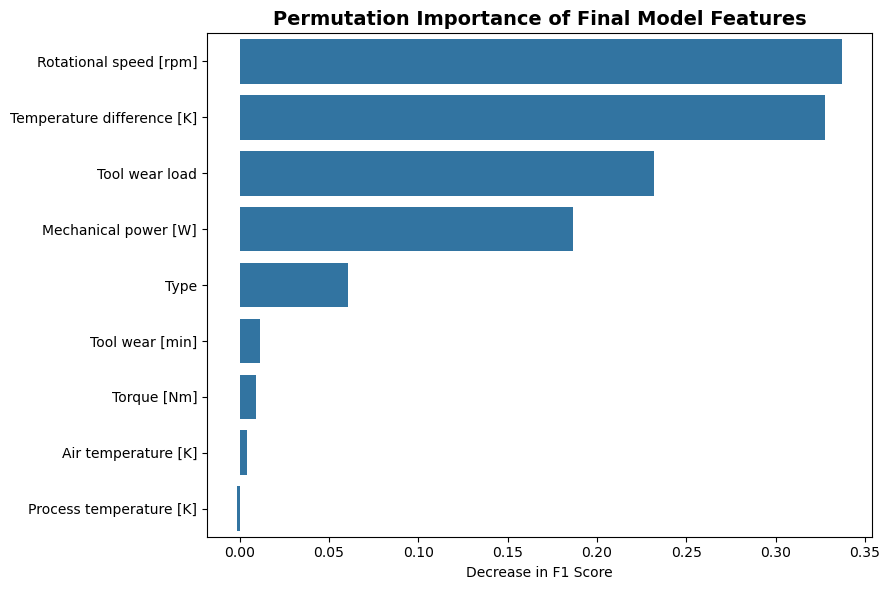

In [104]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=permutation_df,
    x="Importance",
    y="Feature"
)

plt.title(
    "Permutation Importance of Final Model Features",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Decrease in F1 Score")
plt.ylabel("")

plt.tight_layout()
plt.show()

Permutation importance was used as an additional interpretability method to evaluate how strongly each feature affects model performance.

For each feature, its values are randomly shuffled while the remaining variables are left unchanged. A larger decrease in F1-score indicates that the model relies more heavily on that feature when identifying machine failures.

Using both built-in feature importance and permutation importance provides a more complete view of the variables contributing to model predictions.

## Business Interpretation

The model results indicate that machine failure risk is influenced by a combination of mechanical load, rotational speed, accumulated wear, and thermal operating conditions rather than any single sensor measurement.

This supports the use of predictive maintenance as a multi-variable monitoring approach. Instead of defining maintenance decisions using one fixed limit, the model combines several operating conditions to identify higher-risk machine states.

In a real manufacturing environment, these predictions could be used to prioritize equipment for inspection, increase monitoring frequency, or support preventive maintenance decisions before an unexpected breakdown occurs.

## Final Model Performance Assessment

In [108]:
final_predictions = random_forest_model.predict(X_test)
final_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

final_metrics = {
    "Accuracy": accuracy_score(y_test, final_predictions),
    "Precision": precision_score(y_test, final_predictions),
    "Recall": recall_score(y_test, final_predictions),
    "F1 Score": f1_score(y_test, final_predictions),
    "ROC-AUC": roc_auc_score(y_test, final_probabilities),
    "PR-AUC": average_precision_score(y_test, final_probabilities)
}

pd.DataFrame(
    final_metrics.items(),
    columns=["Metric", "Score"]
).round(3)

,Metric,Score
0,Accuracy,0.992
1,Precision,0.965
2,Recall,0.809
3,F1 Score,0.880
4,ROC-AUC,0.973
5,PR-AUC,0.891


The final Random Forest model achieved strong performance across both overall and failure-specific evaluation metrics. At the default classification threshold of 0.50, the model achieved 96.5% precision and 80.9% recall, resulting in an F1-score of 88.0%.

This means the model identifies the majority of actual machine failures while maintaining a relatively low false-positive rate. The PR-AUC of 0.891 further indicates strong performance despite the highly imbalanced target distribution.

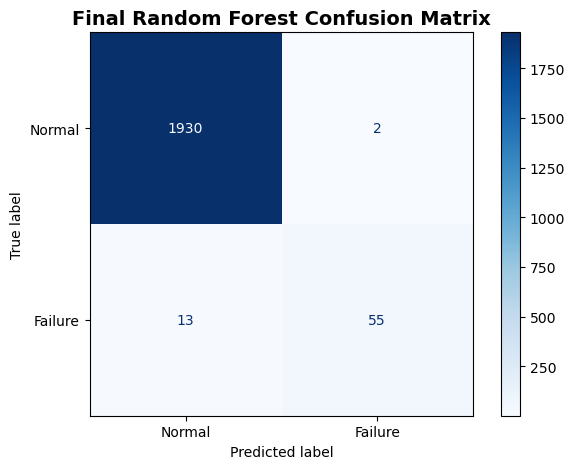

In [109]:
## FInal RF Model Confusion Matrix
ConfusionMatrixDisplay.from_estimator(
    random_forest_model,
    X_test,
    y_test,
    display_labels=["Normal", "Failure"],
    cmap="Blues"
)

plt.title(
    "Final Random Forest Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## Business Oriented Threshold Scenario

In [110]:
threshold_scenarios = []

for threshold in [0.50, 0.20]:
    predictions = (
        final_probabilities >= threshold
    ).astype(int)

    threshold_scenarios.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test,
            predictions
        ),
        "Recall": recall_score(
            y_test,
            predictions
        ),
        "F1 Score": f1_score(
            y_test,
            predictions
        ),
        "Predicted Failures": predictions.sum()
    })

threshold_scenarios = pd.DataFrame(
    threshold_scenarios
)

threshold_scenarios.round(3)

,Threshold,Precision,Recall,F1 Score,Predicted Failures
0,0.5,0.965,0.809,0.880,57
1,0.2,0.787,0.868,0.825,75


## Maintenance Design Logic

In [112]:
def assign_risk_level(probability):
    if probability < 0.20:
        return "Low"
    elif probability < 0.50:
        return "Moderate"
    elif probability < 0.75:
        return "High"
    else:
        return "Critical"

In [113]:
prediction_results = X_test.copy()

prediction_results["Actual Failure"] = y_test.values
prediction_results["Failure Probability"] = final_probabilities

prediction_results["Risk Level"] = (
    prediction_results["Failure Probability"]
    .apply(assign_risk_level)
)

prediction_results[
    [
        "Failure Probability",
        "Risk Level",
        "Actual Failure"
    ]
].head(10)

,Failure Probability,Risk Level,Actual Failure
2997,0.023333,Low,0
4871,0.000000,Low,0
3858,0.030000,Low,0
951,0.000000,Low,0
6463,0.006667,Low,0
3264,0.013333,Low,0
4508,0.020000,Low,0
2100,0.000000,Low,0
7885,0.000000,Low,0
2421,0.000000,Low,0


## Maintenance Actions to Determine Risk Levels - Action Plan Mapping

In [115]:
risk_actions = {
    "Low": "Continue normal operation",
    "Moderate": "Increase monitoring frequency",
    "High": "Schedule maintenance inspection",
    "Critical": "Immediate maintenance review"
}

prediction_results["Recommended Action"] = (
    prediction_results["Risk Level"]
    .map(risk_actions)
)

prediction_results[
    [
        "Failure Probability",
        "Risk Level",
        "Recommended Action",
        "Actual Failure"
    ]
].head(10)

,Failure Probability,Risk Level,Recommended Action,Actual Failure
2997,0.023333,Low,Continue normal operation,0
4871,0.000000,Low,Continue normal operation,0
3858,0.030000,Low,Continue normal operation,0
951,0.000000,Low,Continue normal operation,0
6463,0.006667,Low,Continue normal operation,0
3264,0.013333,Low,Continue normal operation,0
4508,0.020000,Low,Continue normal operation,0
2100,0.000000,Low,Continue normal operation,0
7885,0.000000,Low,Continue normal operation,0
2421,0.000000,Low,Continue normal operation,0


The final model produces a probability of machine failure rather than only a binary prediction. This probability can be translated into operational risk categories and maintenance actions.

For example, low-risk machines may continue normal operation, while higher-risk machines could receive increased monitoring or scheduled inspection. Critical-risk predictions could trigger immediate maintenance review.

The classification threshold can therefore be adjusted according to operational priorities. A conservative threshold reduces unnecessary maintenance alerts, while a lower threshold can detect a greater proportion of potential failures when unplanned downtime carries a higher business cost.

## Final Model Summary

Random Forest was selected as the final model because it provided the strongest balance between failure detection and false-positive control across the evaluated models.

At the default threshold, the model achieved high precision while identifying approximately 81% of actual machine failures. When the decision threshold was reduced to prioritize failure detection, recall increased to approximately 87%, demonstrating that model behavior can be adjusted based on maintenance priorities.

The final model therefore provides both strong predictive performance and flexibility for different operational risk tolerances.

## Objectification and Saving the Final Model

In [117]:
import joblib

joblib.dump(
    random_forest_model,
    "predictive_maintenance_random_forest.pkl"
)

['predictive_maintenance_random_forest.pkl']

In [119]:
#To Load Model
loaded_model = joblib.load(
    "predictive_maintenance_random_forest.pkl"
)

In [121]:
#Model Test
loaded_predictions = loaded_model.predict(X_test)

print(
    "Loaded model accuracy:",
    accuracy_score(y_test, loaded_predictions)
)

Loaded model accuracy: 0.9925


The final Random Forest pipeline was saved as a serialized model artifact. Because preprocessing and classification are contained within the same pipeline, new observations can be passed through the same transformations used during model development before a failure prediction is generated.

In [122]:
final_summary = pd.DataFrame({
    "Project Component": [
        "Business Problem",
        "Target",
        "Final Model",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC",
        "Alternative Threshold"
    ],
    "Result": [
        "Predict machine failure from operating conditions",
        "Machine failure",
        "Random Forest",
        "96.5%",
        "80.9%",
        "88.0%",
        "97.3%",
        "89.1%",
        "0.20 threshold -> 86.8% recall"
    ]
})

final_summary

,Project Component,Result
0,Business Problem,Predict machine failure from operating conditions
1,Target,Machine failure
2,Final Model,Random Forest
3,Precision,96.5%
4,Recall,80.9%
5,F1 Score,88.0%
6,ROC-AUC,97.3%
7,PR-AUC,89.1%
8,Alternative Threshold,0.20 threshold -> 86.8% recall
